# Does Money Buy Wins in MLB? — v2 (robustness check, 2000–2024)

Re-analysis of our USC DSO 510 team project (Group D4). The original class model is replicated in section 2 for comparison.

What v2 adds on top of the original model:
1. **Data check** – why the model uses fewer rows than the 750 team-seasons in the slides.
2. **Inflation fix** – payroll in 2000 and 2025 dollars are not comparable, so payroll is re-expressed relative to that season's league average.
3. **Reverse-causality fix** – `ManagerPoints` comes from Manager of the Year votes, which are cast *after* the season and largely reward winning. v2 re-runs the model without it.
4. **Summary table** – cost of one extra win under each specification.

In [1]:
import os
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt

# Reads data/df_final_merged.csv from this repo.
# In Colab: upload the CSV or clone the repo first, or set CSV_PATH.
CSV_PATH = os.environ.get('CSV_PATH', 'data/df_final_merged.csv')

df = pd.read_csv(CSV_PATH)
df['Payroll'] = df['Payroll'].astype(str).str.replace(',', '', regex=False).astype(float)
df = df.rename(columns={'Win Total': 'Win_Total'})
print(df.shape)
df.head()

(721, 18)


,yearID,teamID,name,attendance,distinct_players,avg_age,avg_experience,count_bats_R,count_bats_L,count_bats_B,count_throws_R,count_throws_L,count_throws_S,Year,Team,Payroll,Win_Total,ManagerPoints
0,2000,ANA,Anaheim Angels,2066982,45,28.800000,4.111111,28,14,3,35,10,0,2000,Anaheim Angels,51464167.0,82,8
1,2000,ARI,Arizona Diamondbacks,2942251,41,30.512195,6.853659,23,14,4,31,10,0,2000,Arizona Diamondbacks,81027833.0,85,0
2,2000,ATL,Atlanta Braves,3234304,47,30.212766,6.106383,32,10,5,40,7,0,2000,Atlanta Braves,84537836.0,95,478
3,2000,BAL,Baltimore Orioles,3297031,50,29.720000,5.920000,35,14,1,41,9,0,2000,Baltimore Orioles,81447435.0,74,0
4,2000,BOS,Boston Red Sox,2585895,52,30.269231,6.153846,33,14,5,42,10,0,2000,Boston Red Sox,77940333.0,85,175


## 1. Data check: how many team-seasons, and which are missing?

In [2]:
cols = ['attendance', 'distinct_players', 'avg_age', 'ManagerPoints', 'Payroll', 'Win_Total']
print('Rows in file:', len(df))
print('Rows by year (2020 should be absent):')
print(df.groupby('Year').size().to_string())
print('\nMissing values per model column:')
print(df[cols].isna().sum().to_string())
missing = df[df[cols].isna().any(axis=1)]
print('\nRows dropped by the regression:', len(missing))
missing[['Year', 'Team'] + cols].head(40)

Rows in file: 721
Rows by year (2020 should be absent):
Year
2000    30
2001    30
2002    30
2003    30
2004    30
2005    30
2006    30
2007    30
2008    30
2009    30
2010    30
2011    30
2012    30
2013    30
2014    30
2015    30
2016    30
2017    30
2018    30
2019    30
2021    30
2022    31
2023    30
2024    30

Missing values per model column:
attendance          0
distinct_players    0
avg_age             0
ManagerPoints       0
Payroll             0
Win_Total           0

Rows dropped by the regression: 0


,Year,Team,attendance,distinct_players,avg_age,ManagerPoints,Payroll,Win_Total


**Findings from the data check**
- The data covers **2000–2024** (24 seasons, 2020 excluded), not 2000–2025 as the slides say. 24 × 30 teams = 720.
- The 721st row is a **duplicate**: the 2022 Washington Nationals appear twice with different payroll and wins. The real 2022 Nationals finished 55–107, so the 71-win row is wrong and is dropped below.

In [3]:
dup = df[df.duplicated(['Year', 'Team'], keep=False)]
print(dup[['Year', 'Team', 'Payroll', 'Win_Total']])
df_orig = df.copy()   # keep the original 721 rows to replicate the slides exactly
df = df[~((df['Year'] == 2022) & (df['Team'] == 'Washington Nationals') & (df['Win_Total'] == 71))].reset_index(drop=True)
print('Rows after fix:', len(df))

     Year                  Team      Payroll  Win_Total
659  2022  Washington Nationals   79983095.0         71
660  2022  Washington Nationals  114623095.0         55
Rows after fix: 720


## 2. Baseline: the original model (should match the slides)

In [4]:
base_formula = 'Win_Total ~ attendance + distinct_players + avg_age + ManagerPoints + Payroll'
m_base = smf.ols(base_formula, data=df_orig).fit()   # original 721 rows, to match the slides
print(m_base.summary().tables[1])
print('n =', int(m_base.nobs), '| R2 =', round(m_base.rsquared, 3))

m_single = smf.ols('Win_Total ~ Payroll', data=df_orig).fit()
print('\nSingle-variable: n =', int(m_single.nobs), '| R2 =', round(m_single.rsquared, 3))

                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept           19.2697     12.518      1.539      0.124      -5.307      43.847
attendance        2.135e-06   6.59e-07      3.238      0.001     8.4e-07    3.43e-06
distinct_players    -0.4358      0.061     -7.160      0.000      -0.555      -0.316
avg_age              2.4333      0.437      5.566      0.000       1.575       3.292
ManagerPoints        0.0275      0.002     14.394      0.000       0.024       0.031
Payroll           4.702e-08   8.43e-09      5.577      0.000    3.05e-08    6.36e-08
n = 721 | R2 = 0.481

Single-variable: n = 721 | R2 = 0.093


## 3. Inflation fix: payroll relative to league average that season

`payroll_rel = team payroll / league-average payroll in the same year`. A value of 1.5 means the team spent 50% more than the average team that year. We also add attendance relative to the season average for the same reason.

In [5]:
df['payroll_rel'] = df['Payroll'] / df.groupby('Year')['Payroll'].transform('mean')
df['attendance_rel'] = df['attendance'] / df.groupby('Year')['attendance'].transform('mean')

league_avg = df.groupby('Year')['Payroll'].mean() / 1e6
print('League-average payroll ($M):  2000 =', round(league_avg.iloc[0], 1), '| last year =', round(league_avg.iloc[-1], 1))

rel_formula = 'Win_Total ~ attendance_rel + distinct_players + avg_age + ManagerPoints + payroll_rel'
m_rel = smf.ols(rel_formula, data=df).fit()
print(m_rel.summary().tables[1])
print('n =', int(m_rel.nobs), '| R2 =', round(m_rel.rsquared, 3))

League-average payroll ($M):  2000 = 55.7 | last year = 153.7
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept           19.2689     13.631      1.414      0.158      -7.492      46.030
attendance_rel      12.0968      1.791      6.755      0.000       8.581      15.613
distinct_players    -0.3300      0.054     -6.070      0.000      -0.437      -0.223
avg_age              2.1827      0.475      4.596      0.000       1.250       3.115
ManagerPoints        0.0269      0.002     13.944      0.000       0.023       0.031
payroll_rel         -0.0269      1.345     -0.020      0.984      -2.667       2.613
n = 720 | R2 = 0.475


## 4. Reverse-causality fix: drop ManagerPoints

Manager of the Year votes are cast after the season, and voters mostly reward teams that won. So part of the 'manager effect' is wins explaining votes, not votes explaining wins. If payroll's coefficient rises once ManagerPoints is removed, the original model was crediting the manager for some of what money bought.

In [6]:
nomgr_formula = 'Win_Total ~ attendance_rel + distinct_players + avg_age + payroll_rel'
m_nomgr = smf.ols(nomgr_formula, data=df).fit()
print(m_nomgr.summary().tables[1])
print('n =', int(m_nomgr.nobs), '| R2 =', round(m_nomgr.rsquared, 3))

                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept           15.8059     15.362      1.029      0.304     -14.353      45.965
attendance_rel      16.1326      1.992      8.098      0.000      12.222      20.044
distinct_players    -0.4527      0.060     -7.487      0.000      -0.571      -0.334
avg_age              2.4768      0.535      4.631      0.000       1.427       3.527
payroll_rel         -0.5544      1.515     -0.366      0.714      -3.529       2.420
n = 720 | R2 = 0.332


## 5. Why does payroll 'disappear'? Attendance is doing the same job

After the inflation fix, payroll is no longer significant. That is not because money stopped mattering:
- Inflation-adjusted payroll **on its own** is a *stronger* predictor than nominal payroll (compare R² below).
- Relative payroll and relative attendance are highly correlated: big-market, high-revenue teams both draw crowds and spend.
- Same-season attendance is also partly an **outcome** of winning (fans show up for good teams), the same problem as ManagerPoints.

So the defensible model drops both after-the-fact variables and keeps only things known before or independent of the result: payroll, roster churn, and age.

In [7]:
print('corr(payroll_rel, attendance_rel) =', round(df['payroll_rel'].corr(df['attendance_rel']), 3))
print('corr(Payroll nominal, wins)        =', round(df['Payroll'].corr(df['Win_Total']), 3))
print('corr(payroll_rel, wins)            =', round(df['payroll_rel'].corr(df['Win_Total']), 3))

m_rel_single = smf.ols('Win_Total ~ payroll_rel', data=df).fit()
print('\nPayroll alone, inflation-adjusted: R2 =', round(m_rel_single.rsquared, 3), '(vs', round(m_single.rsquared, 3), 'nominal)')

m_final = smf.ols('Win_Total ~ payroll_rel + distinct_players + avg_age', data=df).fit()
print('\nFINAL MODEL: payroll_rel + distinct_players + avg_age')
print(m_final.summary().tables[1])
print('n =', int(m_final.nobs), '| R2 =', round(m_final.rsquared, 3))
lo, hi = m_final.conf_int().loc['payroll_rel']
print(f'Each +10% of league-average payroll -> {m_final.params.payroll_rel*0.1:.2f} wins (95% CI {lo*0.1:.2f} to {hi*0.1:.2f})')

corr(payroll_rel, attendance_rel) = 0.755
corr(Payroll nominal, wins)        = 0.305
corr(payroll_rel, wins)            = 0.388

Payroll alone, inflation-adjusted: R2 = 0.15 (vs 0.093 nominal)

FINAL MODEL: payroll_rel + distinct_players + avg_age
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept            4.9614     15.978      0.311      0.756     -26.409      36.332
payroll_rel          7.2138      1.224      5.892      0.000       4.810       9.618
distinct_players    -0.5001      0.063     -7.959      0.000      -0.624      -0.377
avg_age              3.2219      0.550      5.857      0.000       2.142       4.302
n = 720 | R2 = 0.271
Each +10% of league-average payroll -> 0.72 wins (95% CI 0.48 to 0.96)


## 6. Summary: what does one extra win cost?

In [8]:
avg_payroll_m = df['Payroll'].mean() / 1e6
last_year = int(df['Year'].max())
avg_last_m = df.loc[df['Year'] == last_year, 'Payroll'].mean() / 1e6

def per_win_raw(m):
    return 1 / m.params['Payroll'] / 1e6

def per_win_rel(m, base_m):
    # wins per +1.0 of payroll_rel (= spending one extra league-average payroll)
    return base_m / m.params['payroll_rel']

rows = [
    ('Single variable (nominal $)', m_single, per_win_raw(m_single), None),
    ('Original 5-variable (nominal $)', m_base, per_win_raw(m_base), None),
    ('Inflation-adjusted', m_rel, None, per_win_rel(m_rel, avg_last_m)),
    ('Inflation-adjusted, no ManagerPoints', m_nomgr, None, per_win_rel(m_nomgr, avg_last_m)),
    ('Inflation-adjusted, payroll alone', m_rel_single, None, per_win_rel(m_rel_single, avg_last_m)),
    ('FINAL: payroll + roster churn + age', m_final, None, per_win_rel(m_final, avg_last_m)),
]
summary = pd.DataFrame([{
    'Model': name,
    'n': int(m.nobs),
    'R2': round(m.rsquared, 3),
    '$M per extra win (nominal, all years pooled)': None if raw is None else round(raw, 1),
    f'$M per extra win (in {last_year} dollars)': None if rel is None else round(rel, 1),
} for name, m, raw, rel in rows])
pvals = [m.pvalues.get('Payroll', m.pvalues.get('payroll_rel')) for _, m, _, _ in rows]
summary['payroll p-value'] = [round(p, 3) for p in pvals]
price_cols = [c for c in summary.columns if c.startswith('$M')]
summary.loc[summary['payroll p-value'] > 0.05, price_cols] = None  # payroll not significant -> no meaningful price
summary

,Model,n,R2,"$M per extra win (nominal, all years pooled)",$M per extra win (in 2024 dollars),payroll p-value
0,Single variable (nominal $),721,0.093,14.0,NaN,0.000
1,Original 5-variable (nominal $),721,0.481,21.3,NaN,0.000
2,Inflation-adjusted,720,0.475,NaN,NaN,0.984
3,"Inflation-adjusted, no ManagerPoints",720,0.332,NaN,NaN,0.714
4,"Inflation-adjusted, payroll alone",720,0.150,NaN,13.1,0.000
5,FINAL: payroll + roster churn + age,720,0.271,NaN,21.3,0.000


Wins per +1 SD, inflation-adjusted WITH ManagerPoints:
distinct_players   -2.06
payroll_rel        -0.01
avg_age             1.97
attendance_rel      3.50
ManagerPoints       4.80

Wins per +1 SD, FINAL model:
distinct_players   -3.12
payroll_rel         2.89
avg_age             2.90


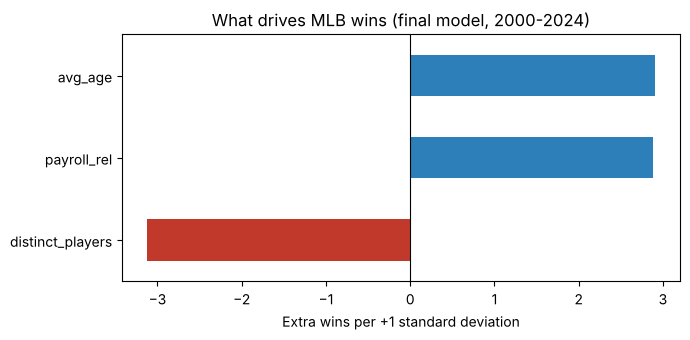

In [9]:
# Standardized effect sizes for the final model: wins per 1 SD change
final_vars = ['distinct_players', 'avg_age', 'payroll_rel']
sd = df[final_vars].std()
std_effect = (m_final.params[final_vars] * sd).sort_values()

full_vars = ['attendance_rel', 'distinct_players', 'avg_age', 'ManagerPoints', 'payroll_rel']
std_effect_full = (m_rel.params[full_vars] * df[full_vars].std()).sort_values()

print('Wins per +1 SD, inflation-adjusted WITH ManagerPoints:')
print(std_effect_full.round(2).to_string())
print('\nWins per +1 SD, FINAL model:')
print(std_effect.round(2).to_string())

fig, ax = plt.subplots(figsize=(7, 3.5))
std_effect.plot.barh(ax=ax, color=['#c0392b' if v < 0 else '#2c7fb8' for v in std_effect])
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Extra wins per +1 standard deviation')
ax.set_title('What drives MLB wins (final model, 2000-2024)')
plt.tight_layout(); plt.show()

## 7. Limitations (still true after v2)
- Observational data: payroll is not randomly assigned, so this is association, not a causal effect.
- Reverse causality also runs through payroll: winning teams earn more revenue and can then spend more.
- `distinct_players` partly measures injuries and mid-season sell-offs, which are themselves caused by losing.
- One season per row; no team fixed effects, so stable team traits (market size, ownership) are not fully controlled.